# 08_03 — Virtual diagnostic: losses and complex models for the shot-to-shot variation

**Goal:** reproduce the BCM's **shot-to-shot variation** (not only its trend), from each shot's own measurements.

Same setup as 08_02: per segment, train before the cut (`CUT`), infer every later shot; stage 1 = trend
(08_01 model, averaged over the previous 51 shots of its own predictions), stage 2 = the shot's deviation from the
previous 51 shots, `y[t] − mean(y[t−51 … t−1])`, from the same deviation of the features. Stage 2 is what this notebook varies:

**Training losses** (on the standardised stage-2 target):
- **MSE** — mean squared error (as before)
- **STD** — standard deviation (variance) of the error; the bias is corrected afterwards on the training shots
- **MAX** — the worst error: smooth version `mean(|e|¹⁰)^(1/10)` (a p-norm close to the maximum, differentiable)
- **CCC** — concordance correlation coefficient, `1 − 2·cov(p, y) / (var p + var y + (mean p − mean y)²)`:
  rewards following each swing **and** reproducing its size (MSE shrinks predictions toward the mean)

**Models:** an MLP (2 × 64, on the shot's feature deviations and raw features) and a GRU (recurrent network over the
deviations of the last `W` shots + the same inputs as the MLP). Each is trained 3 times (seeds) and the 3 are averaged.
Early stopping on the validation block (last `VAL_FRACTION` of the training shots), with the same loss.
Baselines: 08_01 model, 08_02 Ridge + extra trees (MSE), and the same rescaled to the measured fluctuation size
("de-shrunk").

**Scores on the test shots with beam** (shots below 20% of the median — no beam / BCM glitch — are left out of
training and scores; they would make *max error* measure only those glitches):
- shot-to-shot (on the fluctuation = value − 51-shot centred rolling mean): **correlation**, **size**
  (std inferred / std measured; 1 = same size), **CCC**, **explained variance**
- every shot: **per-shot RMSE**, **error std**, **99th percentile** and **maximum** of |error|, all relative to the mean charge

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(8)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"
OUT = REPO / "results" / "virtual_diagnostic"
OUT.mkdir(parents=True, exist_ok=True)

CUT = 0.7
VAL_FRACTION = 0.2
K = 51             # shots: trend window and fluctuation smoothing
W = 8              # GRU: number of past shots seen
SEEDS = [0, 1, 2]
MIN_VALID = 500
NO_BEAM = 0.2

INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"
COLORS = {"08_01 model": "#8a8985", "Ridge + extra trees (08_02)": "#2a78d6", "MLP · CCC": "#eb6834"}

manifest = json.loads((DATASETS / "manifest.json").read_text())
segments = {}
for info in manifest["segments"]:
    z = np.load(DATASETS / info["file"])
    if z["valid"].sum() >= MIN_VALID:
        segments[info["segment"]] = {"X": z["X"], "y": z["y"], "valid": z["valid"], "run": info["run"]}
print(f"{len(segments)} segments: {list(segments)}")

7 segments: [0, 1, 3, 4, 5, 6, 7]


## Building blocks

In [2]:
def past_mean(a):
    """Mean of the previous K rows (causal, excludes the current one)."""
    return pd.DataFrame(a).shift(1).rolling(K, min_periods=1).mean().bfill().to_numpy()


def smooth(a):
    return pd.Series(a).rolling(K, center=True, min_periods=1).mean().to_numpy()


def fast(a):
    return a - smooth(a)


class LinearPlusTrees(BaseEstimator, RegressorMixin):
    def __init__(self, linear, trees):
        self.linear, self.trees = linear, trees

    def fit(self, X, y):
        self.linear_ = clone(self.linear).fit(X, y)
        self.trees_ = clone(self.trees).fit(X, y - self.linear_.predict(X))
        return self

    def predict(self, X):
        return self.linear_.predict(X) + self.trees_.predict(X)


def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))


def stage1():
    return LinearPlusTrees(ridge(), HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=50, l2_regularization=1.0, random_state=0))


def ridge_extra_trees():
    return LinearPlusTrees(ridge(), make_pipeline(SimpleImputer(strategy="median"), ExtraTreesRegressor(
        n_estimators=400, min_samples_leaf=10, max_features=0.5, n_jobs=-1, random_state=0)))


# ---- training losses (p = prediction, t = target, both standardised) ----
def loss_mse(p, t):
    return ((p - t) ** 2).mean()


def loss_std(p, t):
    return (p - t).var()


def loss_max(p, t):
    return ((p - t).abs() ** 10).mean() ** 0.1


def loss_ccc(p, t):
    pm, tm = p.mean(), t.mean()
    cov = ((p - pm) * (t - tm)).mean()
    return 1 - 2 * cov / (p.var(unbiased=False) + t.var(unbiased=False) + (pm - tm) ** 2)


LOSSES = {"MSE": loss_mse, "STD": loss_std, "MAX": loss_max, "CCC": loss_ccc}


class MLP(nn.Module):
    def __init__(self, d_now, d_seq):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_now, 64), nn.GELU(), nn.Dropout(0.1),
                                 nn.Linear(64, 64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 1))

    def forward(self, now, seq):
        return self.net(now).squeeze(-1)


class GRUNet(nn.Module):
    def __init__(self, d_now, d_seq):
        super().__init__()
        self.gru = nn.GRU(d_seq, 32, batch_first=True)
        self.head = nn.Sequential(nn.Linear(32 + d_now, 64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 1))

    def forward(self, now, seq):
        _, h = self.gru(seq)
        return self.head(torch.cat([h[-1], now], dim=1)).squeeze(-1)


ARCHS = {"MLP": MLP, "GRU": GRUNet}


def train_net(arch, loss, now, seq, target, fit, val, seed):
    """Train on `fit` rows, early-stop on `val` rows (same loss); predict every row."""
    torch.manual_seed(seed)
    model = ARCHS[arch](now.shape[1], seq.shape[2])
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    N, S, T = (torch.tensor(a, dtype=torch.float32) for a in (now, seq, target))
    i_fit, i_val = np.flatnonzero(fit), np.flatnonzero(val)
    rng = np.random.default_rng(seed)
    best, best_state, wait = np.inf, None, 0
    for _ in range(200):
        model.train()
        for b in np.array_split(rng.permutation(i_fit), max(1, len(i_fit) // 256)):
            opt.zero_grad()
            loss(model(N[b], S[b]), T[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            lv = loss(model(N[i_val], S[i_val]), T[i_val]).item()
        if lv < best - 1e-5:
            best, best_state, wait = lv, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= 15:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        return model(N, S).numpy()


def scores(y, p):
    e, fy, fp = y - p, fast(y), fast(p)
    return {"fluct corr": np.corrcoef(fy, fp)[0, 1],
            "fluct size": fp.std() / fy.std(),
            "fluct CCC": 2 * np.cov(fy, fp, bias=True)[0, 1] / (fy.var() + fp.var() + (fy.mean() - fp.mean()) ** 2),
            "s2s explained": 1 - np.var(fast(e)) / np.var(fy),
            "per shot": np.sqrt(np.mean(e**2)) / y.mean(),
            "err std": e.std() / y.mean(),
            "p99 err": np.percentile(np.abs(e), 99) / y.mean(),
            "max err": np.max(np.abs(e)) / y.mean()}


HIGHER_BETTER = ["fluct corr", "fluct CCC", "s2s explained"]

## Train everything (~3 min)

In [3]:
test_scores, val_scores, test_preds, splits = {}, {}, {}, {}
t_start = time.time()
for k, s in segments.items():
    X, y, v = s["X"], s["y"], s["valid"]
    n = len(y)
    rows = np.arange(n)
    cut_row, val_row = int(CUT * n), int((1 - VAL_FRACTION) * int(CUT * n))
    beam = y > NO_BEAM * np.median(y[v & (rows < cut_row)])
    fit = v & beam & (rows < val_row)
    val = v & beam & (rows >= val_row) & (rows < cut_row)
    train = fit | val
    test = v & beam & (rows >= cut_row)

    # `full`: fitted on all training shots -> scored on the test shots
    # `held`: fitted on the fit shots only  -> scored on the validation block (to choose a model without peeking)
    s1 = stage1().fit(X[train], y[train]).predict(X)
    s1_fit = stage1().fit(X[fit], y[fit]).predict(X)
    trend, trend_fit = past_mean(s1[:, None])[:, 0], past_mean(s1_fit[:, None])[:, 0]
    X_dev = X - past_mean(X)
    y_dev = y - past_mean(y[:, None])[:, 0]

    full, held = {"08_01 model": s1}, {"08_01 model": s1_fit}
    rf = ridge_extra_trees().fit(X_dev[fit], y_dev[fit]).predict(X_dev)
    size = np.std(y_dev[val]) / np.std(rf[val])                      # fluctuation size missing on validation
    re = ridge_extra_trees().fit(X_dev[train], y_dev[train]).predict(X_dev)
    full["Ridge + extra trees (08_02)"], held["Ridge + extra trees (08_02)"] = trend + re, trend_fit + rf
    full["Ridge + extra trees, de-shrunk"] = trend + size * re
    held["Ridge + extra trees, de-shrunk"] = trend_fit + rf            # size set on validation: no honest val score

    # neural stage 2: inputs standardised on the fit shots, NaN -> 0 (the mean)
    z = lambda a: np.nan_to_num((a - np.nanmean(a[fit], 0)) / (np.nanstd(a[fit], 0) + 1e-12))
    zdev = z(X_dev)
    now = np.hstack([zdev, z(X)])
    seq = np.stack([np.roll(zdev, lag, axis=0) for lag in range(W - 1, -1, -1)], axis=1)
    seq[: W - 1] = 0
    tm, ts = y_dev[fit].mean(), y_dev[fit].std()
    for arch in ARCHS:
        for lname, lf in LOSSES.items():
            out = np.mean([train_net(arch, lf, now, seq, (y_dev - tm) / ts, fit, val, seed) for seed in SEEDS], axis=0)
            dev = out * ts + tm
            dev += np.mean(y_dev[fit] - dev[fit])                    # bias correction (needed for STD)
            full[f"{arch} · {lname}"] = trend + dev      # stage 2 is trained on the fit shots only, early-stopped on val
            held[f"{arch} · {lname}"] = trend_fit + dev

    test_preds[k] = {m: p[test] for m, p in full.items()}
    test_scores[k] = pd.DataFrame({m: scores(y[test], p[test]) for m, p in full.items()}).T
    val_scores[k] = pd.DataFrame({m: scores(y[val], p[val]) for m, p in held.items()}).T
    splits[k] = {"test": test, "cut_row": cut_row}
    print(f"segment {k}: done after {time.time() - t_start:.0f} s")

METHODS = list(test_scores[next(iter(segments))].index)
METRICS = list(test_scores[next(iter(segments))].columns)

segment 0: done after 19 s


segment 1: done after 43 s


segment 3: done after 58 s


segment 4: done after 66 s


segment 5: done after 91 s


segment 6: done after 104 s


segment 7: done after 113 s


## All models × all metrics (mean over segments)

Colour = rank within the column (darker = better), so metrics with different scales can be compared.

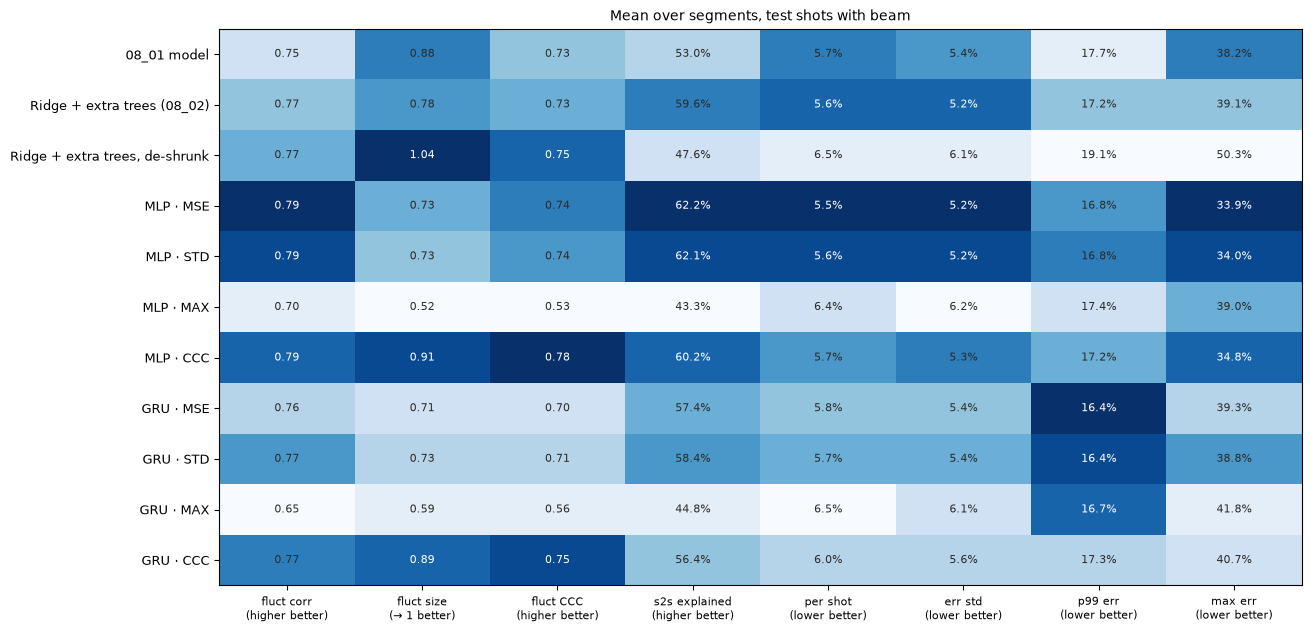

In [4]:
mean = pd.concat(test_scores).groupby(level=1).mean().loc[METHODS, METRICS]
rank = pd.DataFrame({m: mean[m].rank(ascending=m not in HIGHER_BETTER) for m in METRICS})
rank["fluct size"] = (mean["fluct size"] - 1).abs().rank()             # size: closest to 1 is best

fig, ax = plt.subplots(figsize=(13, 0.42 * len(METHODS) + 1.6), layout="constrained")
ax.imshow(rank, cmap="Blues_r", aspect="auto")
for (i, j), val in np.ndenumerate(mean.to_numpy()):
    txt = f"{val:.2f}" if METRICS[j] in ("fluct corr", "fluct size", "fluct CCC") else f"{val:.1%}"
    ax.text(j, i, txt, ha="center", va="center", fontsize=8, color="white" if rank.iloc[i, j] <= 3 else INK)
ax.set_xticks(range(len(METRICS)), [f"{m}\n({'higher' if m in HIGHER_BETTER else ('→ 1' if m == 'fluct size' else 'lower')} better)"
                                     for m in METRICS], fontsize=8)
ax.set_yticks(range(len(METHODS)), METHODS, fontsize=9)
ax.set_title("Mean over segments, test shots with beam", fontsize=10)
fig.savefig(OUT / "losses_models_metrics.png", dpi=130, bbox_inches="tight");

In [5]:
per_segment = pd.concat({k: t[["fluct CCC", "fluct corr", "fluct size", "per shot", "max err"]] for k, t in test_scores.items()},
                        names=["segment", "model"]).unstack("segment")
per_segment.loc[["08_01 model", "Ridge + extra trees (08_02)", "MLP · MSE", "MLP · CCC", "GRU · CCC", "MLP · MAX"]].round(3)

fluct CCC                                     \
segment                             0      1      3      4      5      6   
model                                                                      
08_01 model                     0.805  0.580  0.549  0.591  0.706  0.971   
Ridge + extra trees (08_02)     0.743  0.673  0.545  0.552  0.709  0.980   
MLP · MSE                       0.754  0.742  0.557  0.599  0.685  0.975   
MLP · CCC                       0.827  0.757  0.618  0.661  0.700  0.975   
GRU · CCC                       0.826  0.757  0.615  0.637  0.765  0.974   
MLP · MAX                       0.743  0.438  0.373  0.438  0.367  0.972   

                                   fluct corr                ... per shot  \
segment                          7          0      1      3  ...        5   
model                                                        ...            
08_01 model                  0.931      0.814  0.586  0.609  ...    0.023   
Ridge + extra trees (08_02)  0.933      0.813  0.684  0.617  ...    0.023   
MLP · MSE                    0.890      0.837  0.752  0.626  ...    0.023   
MLP · CCC                    0.927      0.837  0.758  0.628  ...    0.024   
GRU · CCC                    0.707      0.833  0.758  0.629  ...    0.022   
MLP · MAX                    0.353      0.812  0.492  0.571  ...    0.029   

                                          max err                              \
segment                          6      7       0      1      3      4      5   
model                                                                           
08_01 model                  0.010  0.024   0.266  0.369  0.804  0.878  0.168   
Ridge + extra trees (08_02)  0.009  0.023   0.270  0.424  0.825  0.736  0.266   
MLP · MSE                    0.010  0.027   0.249  0.300  0.827  0.548  0.169   
MLP · CCC                    0.010  0.024   0.269  0.301  0.860  0.610  0.177   
GRU · CCC                    0.010  0.042   0.274  0.288  0.864  0.674  0.160   
MLP · MAX                    0.010  0.053   0.236  0.334  0.789  0.553  0.177   

                                           
segment                          6      7  
model                                      
08_01 model                  0.033  0.159  
Ridge + extra trees (08_02)  0.032  0.185  
MLP · MSE                    0.034  0.245  
MLP · CCC                    0.034  0.185  
GRU · CCC                    0.031  0.560  
MLP · MAX                    0.040  0.600  

[6 rows x 35 columns]

## Chosen on validation

Per segment, the model with the best **fluctuation CCC** on the validation block, using versions fitted on the shots
before it (the neural networks also used this block for early stopping, so their validation score is slightly optimistic).
The de-shrunk baseline is excluded: its size factor is set on the validation block itself.

In [6]:
rows = []
for k in segments:
    chosen = val_scores[k]["fluct CCC"].drop("Ridge + extra trees, de-shrunk").idxmax()
    rows.append({"segment": k, "chosen": chosen,
                 **{f"{m}: chosen": test_scores[k].loc[chosen, m] for m in ["fluct CCC", "fluct corr", "fluct size", "per shot"]},
                 **{f"{m}: 08_02": test_scores[k].loc["Ridge + extra trees (08_02)", m] for m in ["fluct CCC", "fluct corr", "fluct size", "per shot"]}})
chosen = pd.DataFrame(rows).set_index("segment")
chosen.round(3)

,chosen,fluct CCC: chosen,fluct corr: chosen,fluct size: chosen,per shot: chosen,fluct CCC: 08_02,fluct corr: 08_02,fluct size: 08_02,per shot: 08_02
segment,,,,,,,,,
0,MLP · CCC,0.827,0.837,0.855,0.064,0.743,0.813,0.651,0.063
1,MLP · STD,0.744,0.753,0.854,0.052,0.673,0.684,0.838,0.051
3,MLP · CCC,0.618,0.628,0.834,0.103,0.545,0.617,0.601,0.104
4,MLP · CCC,0.661,0.661,1.019,0.124,0.552,0.622,0.607,0.116
5,GRU · CCC,0.765,0.767,0.944,0.022,0.709,0.718,0.855,0.023
6,Ridge + extra trees (08_02),0.980,0.980,0.981,0.009,0.980,0.980,0.981,0.009
7,GRU · CCC,0.707,0.792,0.616,0.042,0.933,0.934,0.961,0.023


## Per segment: fluctuation CCC and size

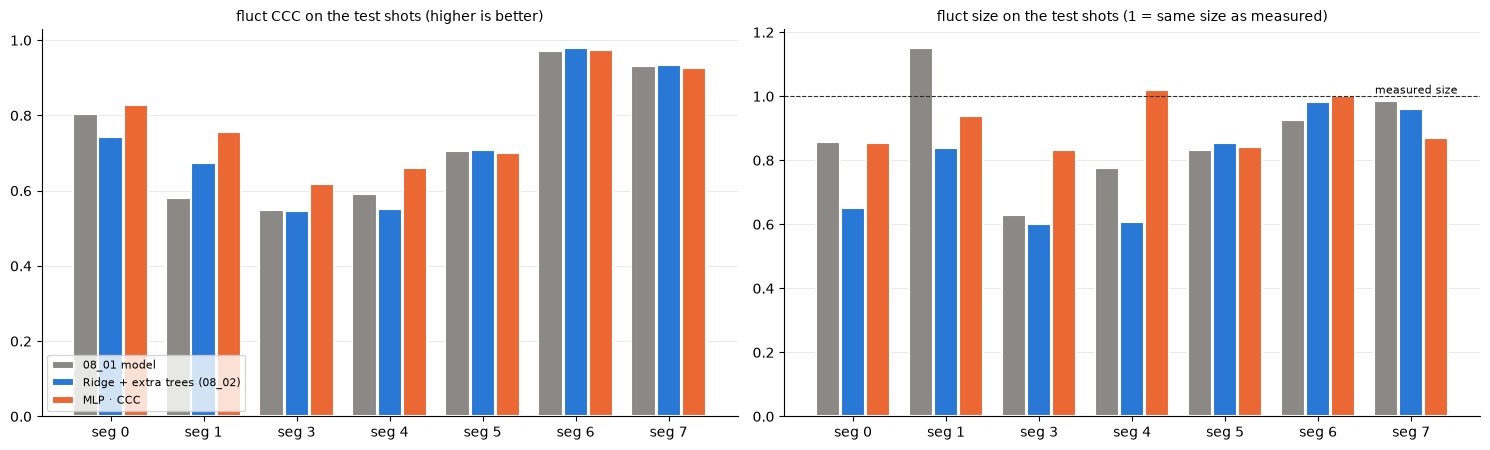

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.arange(len(segments))
for ax, metric, ref in zip(axes, ["fluct CCC", "fluct size"], [None, 1.0]):
    for i, (name, color) in enumerate(COLORS.items()):
        vals = [test_scores[k].loc[name, metric] for k in segments]
        ax.bar(x + (i - 1) * 0.27, vals, width=0.26, color=color, label=name, edgecolor="white", linewidth=1.5)
    if ref is not None:
        ax.axhline(ref, color=INK, lw=0.8, ls="--")
        ax.text(len(segments) - 0.5, ref, " measured size", va="bottom", ha="right", fontsize=8)
    ax.set_xticks(x, [f"seg {k}" for k in segments])
    ax.set_title(f"{metric} on the test shots" + (" (higher is better)" if metric == "fluct CCC" else " (1 = same size as measured)"), fontsize=10)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(OUT / "losses_per_segment.png", dpi=130, bbox_inches="tight")

## Shot by shot: first 150 test shots

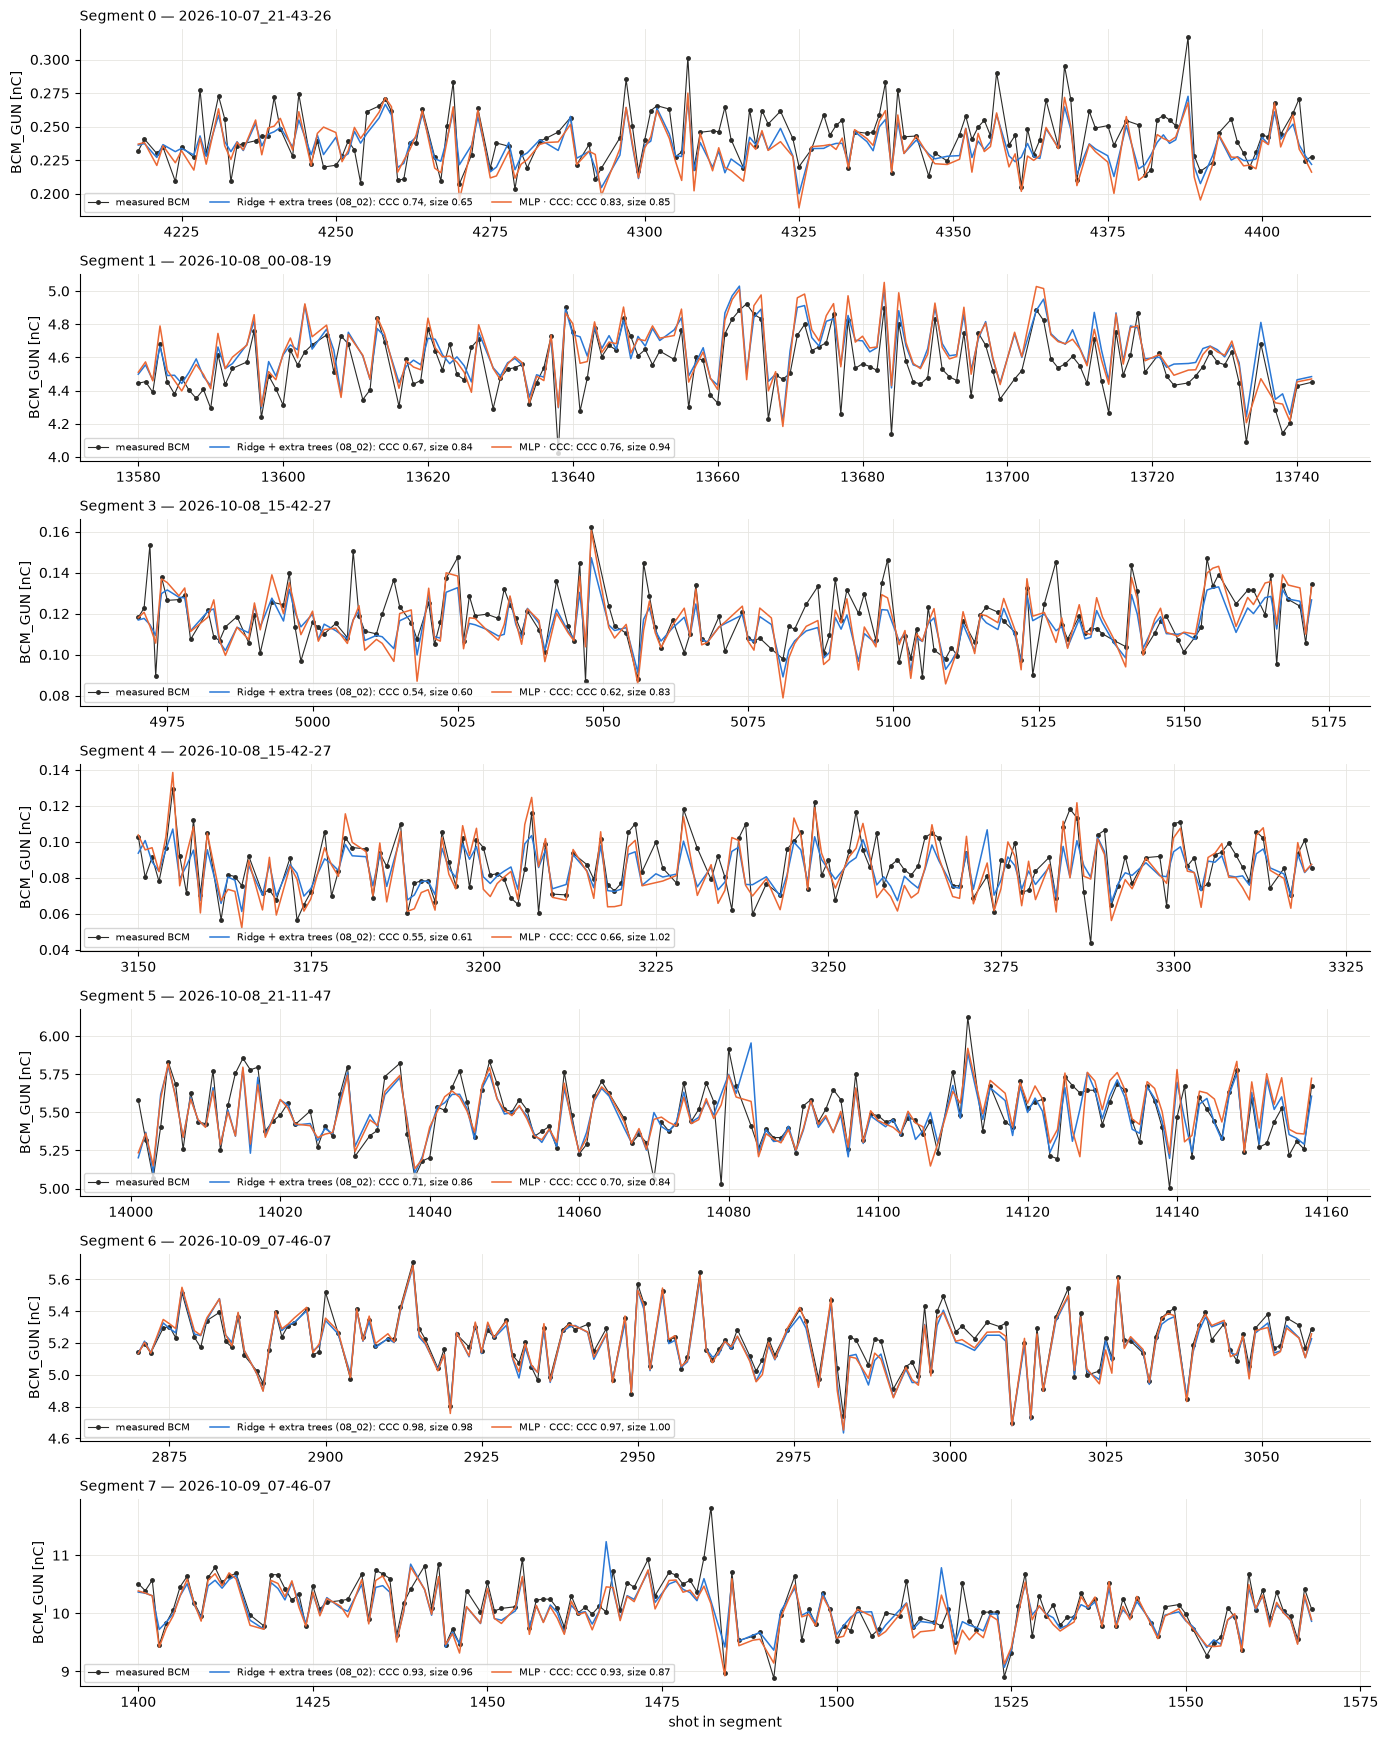

In [8]:
ZOOM = 150
fig, axes = plt.subplots(len(segments), 1, figsize=(14, 2.5 * len(segments)), squeeze=False)
for ax, (k, s) in zip(axes[:, 0], segments.items()):
    shots = np.flatnonzero(splits[k]["test"])[:ZOOM]
    ax.plot(shots, s["y"][shots], "-o", ms=2.5, lw=0.8, color=INK, label="measured BCM")
    for name in ["Ridge + extra trees (08_02)", "MLP · CCC"]:
        sc = test_scores[k].loc[name]
        ax.plot(shots, test_preds[k][name][:ZOOM], lw=1.1, color=COLORS[name],
                label=f"{name}: CCC {sc['fluct CCC']:.2f}, size {sc['fluct size']:.2f}")
    ax.set_title(f"Segment {k} — {s['run'].removeprefix('acquisition_')}", fontsize=10, loc="left")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.legend(fontsize=7, loc="lower left", ncol=3)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[-1, 0].set_xlabel("shot in segment")
fig.tight_layout()
fig.savefig(OUT / "losses_zoom.png", dpi=130, bbox_inches="tight")

## Measured vs inferred fluctuation (MLP · CCC): the 1:1 line is a perfect shot-to-shot match

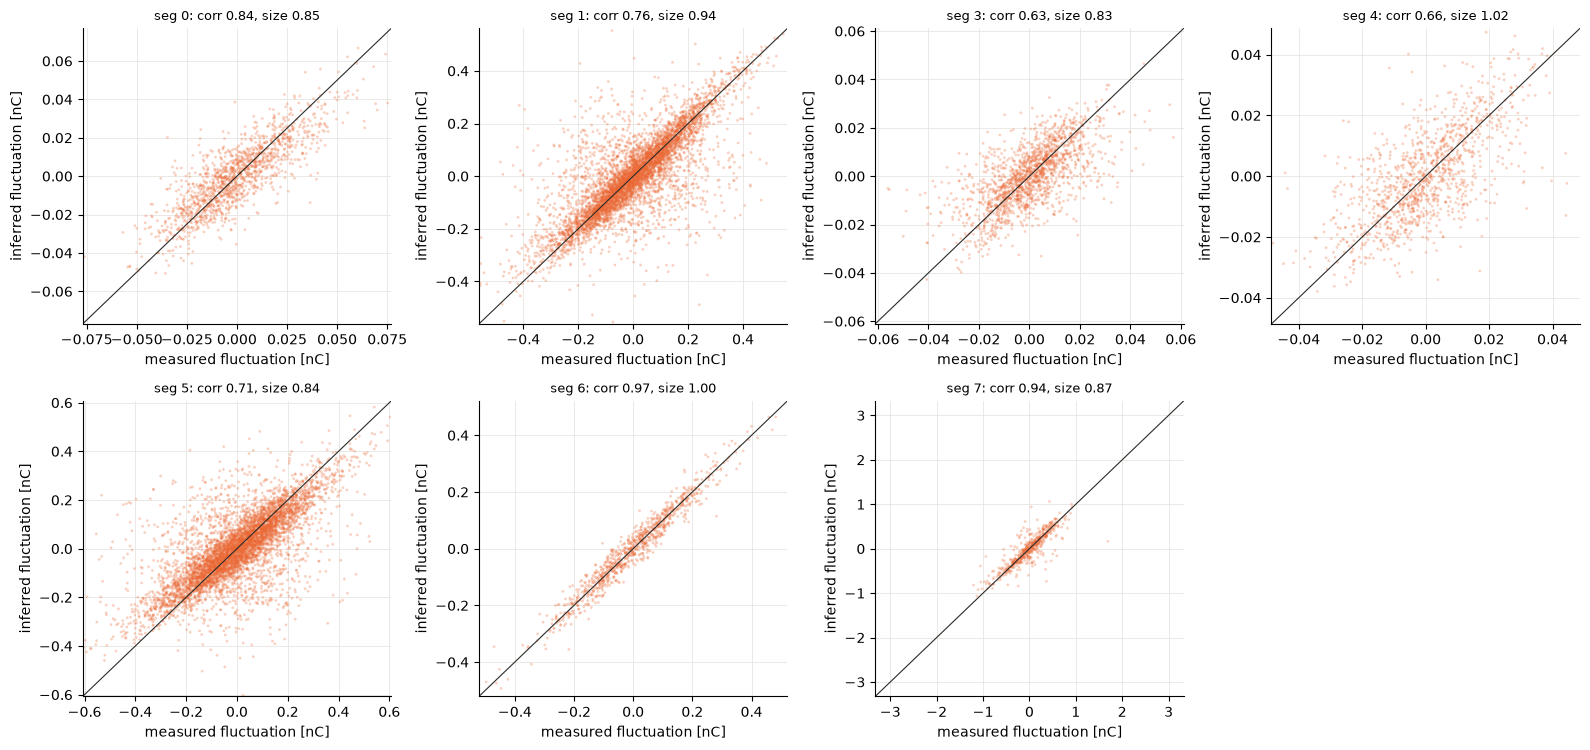

In [9]:
ncols = 4
nrows = int(np.ceil(len(segments) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.8 * nrows), squeeze=False)
for ax, k in zip(axes.ravel(), segments):
    y = segments[k]["y"][splits[k]["test"]]
    fy, fp = fast(y), fast(test_preds[k]["MLP · CCC"])
    ax.scatter(fy, fp, s=4, color=COLORS["MLP · CCC"], alpha=0.3, edgecolors="none")
    lim = np.percentile(np.abs(fy), 99.5) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=INK, lw=0.8)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="measured fluctuation [nC]", ylabel="inferred fluctuation [nC]",
           title=f"seg {k}: corr {np.corrcoef(fy, fp)[0, 1]:.2f}, size {fp.std() / fy.std():.2f}")
    ax.title.set_fontsize(9)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
for ax in axes.ravel()[len(segments):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "losses_fluct_scatter.png", dpi=130, bbox_inches="tight")

## Save the test predictions (used by notebook 08_04)

In [10]:
SAVE = ["MLP · CCC", "Ridge + extra trees (08_02)", "08_01 model"]
frames = []
for k, s in segments.items():
    test = splits[k]["test"]
    frames.append(pd.DataFrame({"segment": k, "run": s["run"], "shot": np.flatnonzero(test), "measured": s["y"][test],
                                **{name: test_preds[k][name] for name in SAVE}}))
pd.concat(frames).to_csv(OUT / "predictions_08_03.csv", index=False)
print(f"saved {OUT / 'predictions_08_03.csv'}")

saved /Users/angilard/Desktop/Fast-Approximate/results/virtual_diagnostic/predictions_08_03.csv
